In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from glob import glob
from dask.distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 35781 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/35781/status,
Dashboard: /proxy/35781/status,Workers: 28
Total threads: 28,Total memory: 126.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42975,Workers: 0
Dashboard: /proxy/35781/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:46239,Total threads: 1
Dashboard: /proxy/44993/status,Memory: 4.50 GiB
Nanny: tcp://127.0.0.1:37285,


In [70]:
paths = glob('/g/data/x77/wgh581/Post_Process/CMIP6_CMIP7_Subset/mlotst*.nc')

In [71]:
ds = {}
for p in paths:
    model = p.split('_')[5]
    ds[model] = xr.open_dataset(p)['mlotst']

In [72]:
for m in list(ds.keys())[1:]:
    ds[m]['time'] = ds['MRI-ESM2-0']['time'].values

In [73]:
ds = xr.Dataset(ds).to_dataarray().rename({'variable':'model'})

In [74]:
ds_feb = ds.groupby('time.month').mean('time').sel(month=2)

In [75]:
ds_sep = ds.groupby('time.month').mean('time').sel(month=9)

In [76]:
land_mask = np.where(np.any(np.isnan(ds), axis=0), 1, np.nan)[0,:,:]
land_mask[23:,73]=np.nan
land_mask = xr.DataArray(land_mask, dims=['lat','lon'], coords={'lat':ds['lat'], 'lon':ds['lon']})

In [77]:
import cmocean as cm
import cartopy.crs as ccrs
import matplotlib.path as mpath

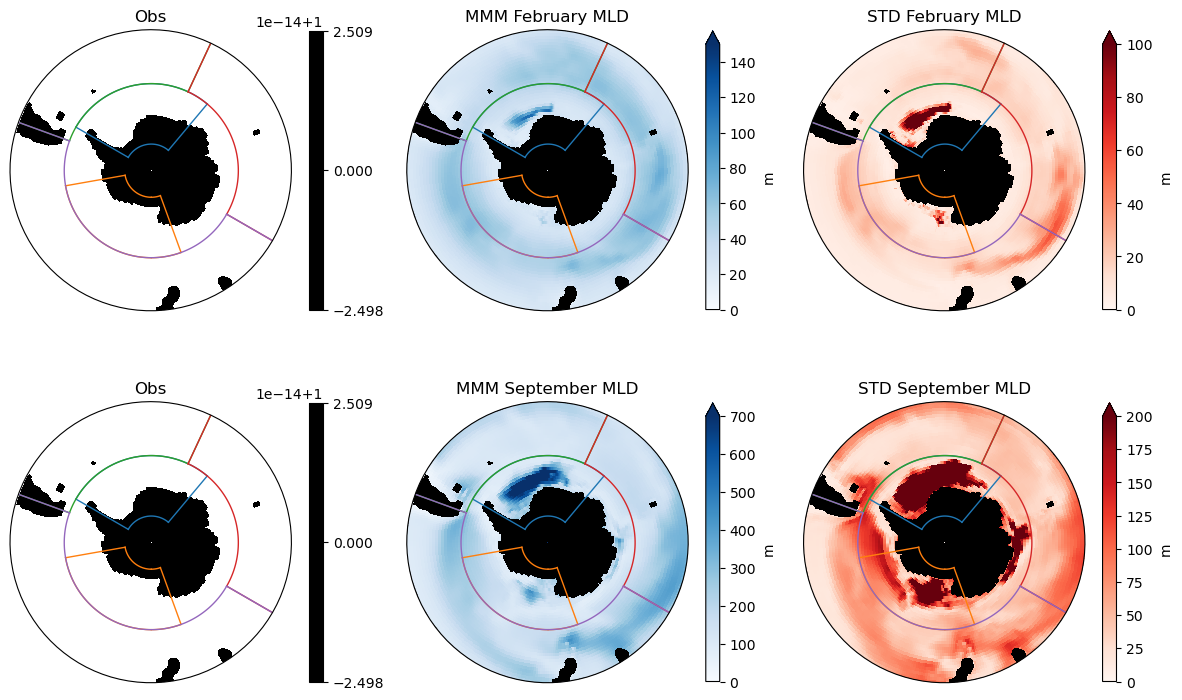

In [81]:
projection = ccrs.SouthPolarStereo()

fig, axs = plt.subplots(2, 3, figsize=(12, 8),
                        subplot_kw={"projection": projection})

for ax in axs.flatten():
    if ax not in [axs[0,0], axs[1,0]]:
        ax.set_facecolor('k')
    ax.set_extent([-280, 80, -80, -40], crs=ccrs.PlateCarree())
    
    theta = np.linspace(0, 2 * np.pi, 100)
    center, radius = [0.5, 0.5], 0.5
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T
    circle = mpath.Path(verts * radius + center)
    ax.set_boundary(circle, transform=ax.transAxes)
    if ax not in [axs[0,0], axs[1,0]]:
        land_mask.plot.contourf(ax=ax, colors=['k'], add_colorbar=False, zorder=2,
                                transform=ccrs.PlateCarree())
    else:
        land_mask.plot.contourf(ax=ax, colors=['k'], cbar_kwargs={'shrink':.7}, zorder=2,
                                transform=ccrs.PlateCarree())
    lat = -80; lon = np.linspace(-60,40,100)
    ax.plot(lon, np.full_like(lon, lat), color='C0', linewidth=1, transform=ccrs.PlateCarree())
    ax.plot([-60,-60], [-80,-58], color='C0', linewidth=1, transform=ccrs.PlateCarree())
    ax.plot([40,40], [-80,-58], color='C0', linewidth=1, transform=ccrs.PlateCarree())
    lat = -58; lon = np.linspace(-60,40,100)
    ax.plot(lon, np.full_like(lon, lat), color='C0', linewidth=1, transform=ccrs.PlateCarree())

    lat = -80; lon = np.linspace(-180,-100,100)
    ax.plot(lon, np.full_like(lon, lat), color='C1', linewidth=1, transform=ccrs.PlateCarree())
    lon = np.linspace(160,180,100)
    ax.plot(lon, np.full_like(lon, lat), color='C1', linewidth=1, transform=ccrs.PlateCarree())
    ax.plot([160,160], [-80,-58], color='C1', linewidth=1, transform=ccrs.PlateCarree())
    ax.plot([-100,-100], [-80,-58], color='C1', linewidth=1, transform=ccrs.PlateCarree())
    lat = -58; lon = np.linspace(-180,-100,100)
    ax.plot(lon, np.full_like(lon, lat), color='C1', linewidth=1, transform=ccrs.PlateCarree())
    lon = np.linspace(160,180,100)
    ax.plot(lon, np.full_like(lon, lat), color='C1', linewidth=1, transform=ccrs.PlateCarree())

    ax.plot([290,290], [-58,-40], color='C2', linewidth=1, transform=ccrs.PlateCarree())
    ax.plot([25,25], [-58,-40], color='C2', linewidth=1, transform=ccrs.PlateCarree())
    lat = -58; lon = np.linspace(-70,25,100)
    ax.plot(lon, np.full_like(lon, lat), color='C2', linewidth=1, transform=ccrs.PlateCarree())

    ax.plot([25,25], [-58,-40], color='C3', linewidth=1, transform=ccrs.PlateCarree())
    ax.plot([120,120], [-58,-40], color='C3', linewidth=1, transform=ccrs.PlateCarree())
    lat = -58; lon = np.linspace(25,120,100)
    ax.plot(lon, np.full_like(lon, lat), color='C3', linewidth=1, transform=ccrs.PlateCarree())

    ax.plot([120,120], [-58,-40], color='C4', linewidth=1, transform=ccrs.PlateCarree())
    ax.plot([290,290], [-58,-40], color='C4', linewidth=1, transform=ccrs.PlateCarree())
    lat = -58; lon = np.linspace(120,290,100)
    ax.plot(lon, np.full_like(lon, lat), color='C4', linewidth=1, transform=ccrs.PlateCarree())
    

ds_feb.mean('model').plot(ax=axs[0,1], vmin=0, vmax=150, cmap='Blues', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             cbar_kwargs={'shrink':.7, 'label':'m'})

ds_sep.mean('model').plot(ax=axs[1,1], vmin=0, vmax=700, cmap='Blues', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             cbar_kwargs={'shrink':.7, 'label':'m'})

ds_feb.std('model').plot(ax=axs[0,2], vmin=0, vmax=100, cmap='Reds', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             cbar_kwargs={'shrink':.7, 'label':'m'})

ds_sep.std('model').plot(ax=axs[1,2], vmin=0, vmax=200, cmap='Reds', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             cbar_kwargs={'shrink':.7, 'label':'m'})
axs[0,0].set_title('Obs');
axs[1,0].set_title('Obs');
axs[0,1].set_title('MMM February MLD');
axs[1,1].set_title('MMM September MLD');
axs[0,2].set_title('STD February MLD');
axs[1,2].set_title('STD September MLD');
plt.tight_layout();
plt.savefig('/g/data/x77/jn8053/11-CMIP7/MLD_FebAug.jpg', bbox_inches='tight')

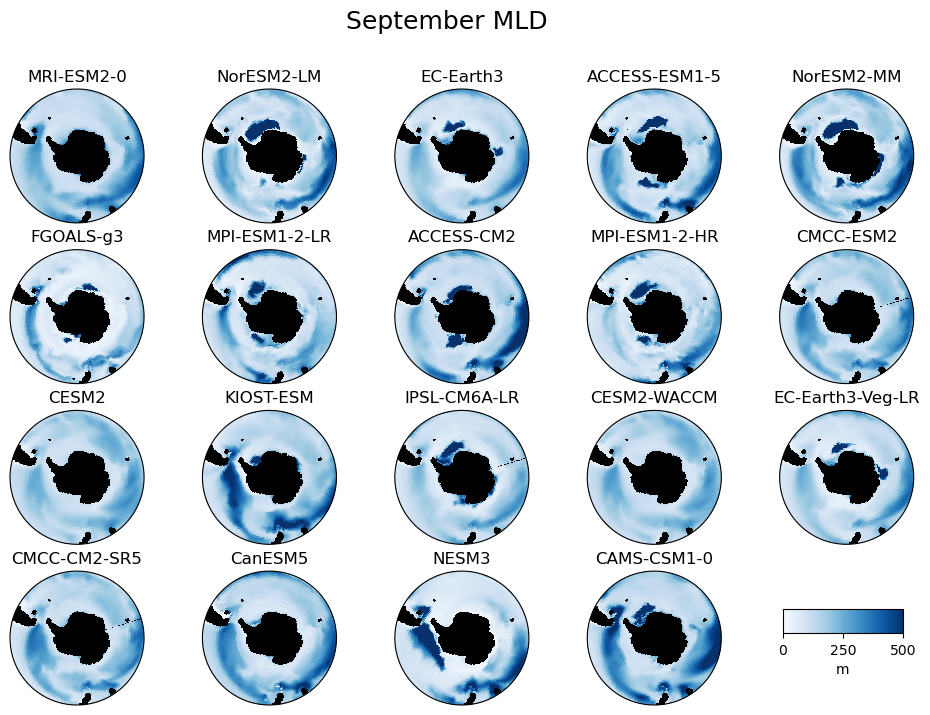

In [82]:
fig, axs = plt.subplots(4, 5, figsize=(12, 8),
                        subplot_kw={"projection": projection})
axs=axs.flatten()
for ax in axs:
    ax.set_facecolor('k')
    ax.set_extent([-280, 80, -80, -40], crs=ccrs.PlateCarree())
    
    theta = np.linspace(0, 2 * np.pi, 100)
    center, radius = [0.5, 0.5], 0.5
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T
    circle = mpath.Path(verts * radius + center)
    ax.set_boundary(circle, transform=ax.transAxes)
    land_mask.plot.contourf(ax=ax, colors=['k'], add_colorbar=False, zorder=2,
                            transform=ccrs.PlateCarree())
n=0
for v in ds_sep['model']:
    c=ds_sep.sel(model=v).plot(ax=axs[n], vmin=0, vmax=500, cmap='Blues', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             add_colorbar=False)
    axs[n].set_title(v.item());
    n+=1
plt.colorbar(c, cax=fig.add_subplot([.78, .2, .1, .03]), orientation='horizontal').set_label('m');
axs[-1].remove();
fig.suptitle('September MLD', fontsize=18);
plt.savefig('/g/data/x77/jn8053/11-CMIP7/MLD_Sep.jpg', bbox_inches='tight')

In [84]:
ds_sep_max = ds_sep.max('lat')

In [96]:
989/2

494.5

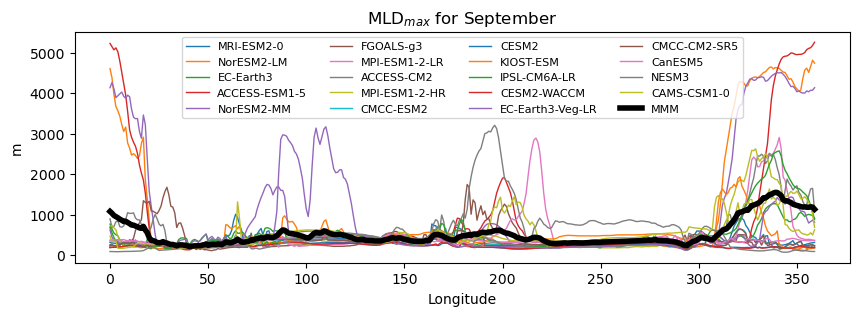

In [92]:
plt.figure(figsize=(10,3))
for v in ds['model'].values:
    ds_sep_max.sel(model=v).plot(linewidth=1, label=v)
ds_sep_max.mean('model').plot(c='k', linewidth=4, label='MMM')
plt.title('MLD$_{max}$ for September');
plt.xlabel('Longitude');
plt.ylabel('m');
plt.legend(ncol=4, fontsize=8);
plt.savefig('/g/data/x77/jn8053/11-CMIP7/MLDmax_vs_lon_Sep.jpg', bbox_inches='tight')

To do: 
1. ~Time series of maximum for different sectors - subduction regions vs subpolar regions~
2. ~Month of maximum~

In [100]:
ds_wedd = ds.where((ds.lon<40) | (ds.lon>300)).where(ds.lat<-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_ross = ds.where((ds.lon<260) & (ds.lon>160)).where(ds.lat<-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_atla = ds.where((ds.lon<25) | (ds.lon>290)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_indi = ds.where((ds.lon>25) & (ds.lon<120)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_paci = ds.where((ds.lon>120) & (ds.lon<290)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')

In [101]:
ds_wedd_mmm = ds.mean('model').where((ds.lon<40) | (ds.lon>300)).where(ds.lat<-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_ross_mmm = ds.mean('model').where((ds.lon<260) & (ds.lon>160)).where(ds.lat<-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_atla_mmm = ds.mean('model').where((ds.lon<25) | (ds.lon>290)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_indi_mmm = ds.mean('model').where((ds.lon>25) & (ds.lon<120)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_paci_mmm = ds.mean('model').where((ds.lon>120) & (ds.lon<290)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')

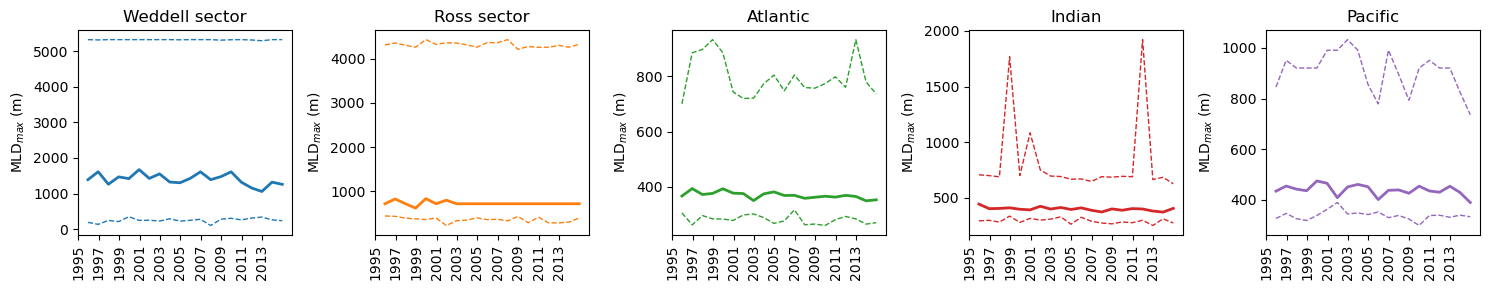

In [169]:
fig, axs = plt.subplots(1, 5, figsize=(15,3))
ds_wedd_mmm.plot(ax=axs[0], c='C0', linewidth=2)
ds_ross_mmm.plot(ax=axs[1], c='C1', linewidth=2)
ds_atla_mmm.plot(ax=axs[2], c='C2', linewidth=2)
ds_indi_mmm.plot(ax=axs[3], c='C3', linewidth=2)
ds_paci_mmm.plot(ax=axs[4], c='C4', linewidth=2)

(ds_wedd.min('model')).plot(ax=axs[0], c='C0', linewidth=1, linestyle='--')
(ds_wedd.max('model')).plot(ax=axs[0], c='C0', linewidth=1, linestyle='--')
(ds_ross.min('model')).plot(ax=axs[1], c='C1', linewidth=1, linestyle='--')
(ds_ross.max('model')).plot(ax=axs[1], c='C1', linewidth=1, linestyle='--')
(ds_atla.min('model')).plot(ax=axs[2], c='C2', linewidth=1, linestyle='--')
(ds_atla.max('model')).plot(ax=axs[2], c='C2', linewidth=1, linestyle='--')
(ds_indi.min('model')).plot(ax=axs[3], c='C3', linewidth=1, linestyle='--')
(ds_indi.max('model')).plot(ax=axs[3], c='C3', linewidth=1, linestyle='--')
(ds_paci.min('model')).plot(ax=axs[4], c='C4', linewidth=1, linestyle='--')
(ds_paci.max('model')).plot(ax=axs[4], c='C4', linewidth=1, linestyle='--')

axs[0].set_title('Weddell sector');
axs[1].set_title('Ross sector');
axs[2].set_title('Atlantic');
axs[3].set_title('Indian');
axs[4].set_title('Pacific');
for ax in axs:
    ax.set_ylabel('MLD$_{max}$ (m)'); ax.set_xlabel('');
    ax.set_xticks(ds.time.values[::24])
    ax.set_xticklabels(np.arange(1995,2015,2),rotation=90);
plt.tight_layout();
plt.savefig('/g/data/x77/jn8053/11-CMIP7/MLDmax_per_sector_timeseries.jpg', bbox_inches='tight')

In [100]:
ds_wedd = ds.where((ds.lon<40) | (ds.lon>300)).where(ds.lat<-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_ross = ds.where((ds.lon<260) & (ds.lon>160)).where(ds.lat<-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_atla = ds.where((ds.lon<25) | (ds.lon>290)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_indi = ds.where((ds.lon>25) & (ds.lon<120)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')
ds_paci = ds.where((ds.lon>120) & (ds.lon<290)).where(ds.lat>-58).max(['lat','lon']).resample(time='1YE').max('time')

In [115]:
years = np.unique(ds.time.dt.year)

In [ ]:
month_wedd_mmm = np.empty(len(years))
n=0
for y in years:
    time_slice = slice(str(y)+'-01-01',str(y)+'-12-31')
    tmp = ds.mean('model').where((ds.lon<40) | (ds.lon>300)).where(ds.lat<-58).max(['lat','lon']).sel(time=time_slice)
    month_wedd_mmm[n] = int(np.where(tmp==ds_wedd_mmm[n].values)[0][0])+1
    n+=1

month_ross_mmm = np.empty(len(years))
n=0
for y in years:
    time_slice = slice(str(y)+'-01-01',str(y)+'-12-31')
    tmp = ds.mean('model').where((ds.lon<260) & (ds.lon>160)).where(ds.lat<-58).max(['lat','lon']).sel(time=time_slice)
    month_ross_mmm[n] = int(np.where(tmp==ds_ross_mmm[n].values)[0][0])+1
    n+=1

month_atla_mmm = np.empty(len(years))
n=0
for y in years:
    time_slice = slice(str(y)+'-01-01',str(y)+'-12-31')
    tmp = ds.mean('model').where((ds.lon<25) | (ds.lon>290)).where(ds.lat>-58).max(['lat','lon']).sel(time=time_slice)
    month_atla_mmm[n] = int(np.where(tmp==ds_atla_mmm[n].values)[0][0])+1
    n+=1

month_indi_mmm = np.empty(len(years))
n=0
for y in years:
    time_slice = slice(str(y)+'-01-01',str(y)+'-12-31')
    tmp = ds.mean('model').where((ds.lon>25) & (ds.lon<120)).where(ds.lat>-58).max(['lat','lon']).sel(time=time_slice)
    month_indi_mmm[n] = int(np.where(tmp==ds_indi_mmm[n].values)[0][0])+1
    n+=1

month_paci_mmm = np.empty(len(years))
n=0
for y in years:
    time_slice = slice(str(y)+'-01-01',str(y)+'-12-31')
    tmp = ds.mean('model').where((ds.lon>120) & (ds.lon<290)).where(ds.lat>-58).max(['lat','lon']).sel(time=time_slice)
    month_paci_mmm[n] = int(np.where(tmp==ds_paci_mmm[n].values)[0][0])+1
    n+=1

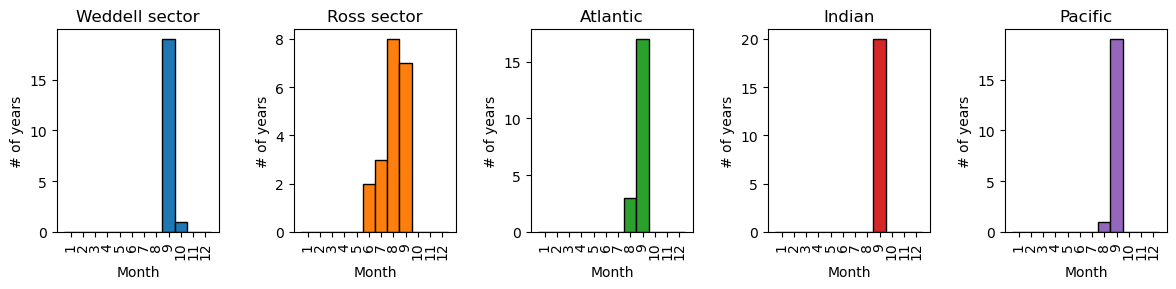

In [152]:
fig, axs = plt.subplots(1, 5, figsize=(12,3))
axs[0].hist(month_wedd_mmm, bins=[i - 0.5 for i in range(1, 14)], edgecolor="black", color='C0')
axs[1].hist(month_ross_mmm, bins=[i - 0.5 for i in range(1, 14)], edgecolor="black", color='C1')
axs[2].hist(month_atla_mmm, bins=[i - 0.5 for i in range(1, 14)], edgecolor="black", color='C2')
axs[3].hist(month_indi_mmm, bins=[i - 0.5 for i in range(1, 14)], edgecolor="black", color='C3')
axs[4].hist(month_paci_mmm, bins=[i - 0.5 for i in range(1, 14)], edgecolor="black", color='C4')

axs[0].set_title('Weddell sector');
axs[1].set_title('Ross sector');
axs[2].set_title('Atlantic');
axs[3].set_title('Indian');
axs[4].set_title('Pacific');
for ax in axs:
    ax.set_ylabel('# of years'); ax.set_xlabel('Month');
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(range(1, 13), rotation=90)
plt.tight_layout();
plt.savefig('/g/data/x77/jn8053/11-CMIP7/MLDmax_month_of_occ.jpg', bbox_inches='tight')

To do: 
1. Look into different MLD definitions